In [1]:
import numpy as np
import numpy.ma as ma
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import statistics
import matplotlib.ticker as mticker
from tqdm import tqdm
from cartopy.util import add_cyclic_point


#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_jja_1940-2023.nc
!ls

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking
dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1990-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_1960.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_MIX_tracked_unfilt_daily_1960.nc


In [3]:
#IMPORT DATASET
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ds = xr.load_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc')
dic = np.load('dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_DIC.npy',allow_pickle=True)
#!cdo selmon,12,1,2 ../sfc_fluxes/latent_heat/ERA5_sfc_lat_heat_daily_northem_2.5x2.5_1940-2023.nc ../sfc_fluxes/latent_heat/ERA5_sfc_lat_heat_daily_northem_2.5x2.5_djf_1940-2023.nc
ds_comp = xr.load_dataset('../IVT/ERA5_IVT_northem_daily_2.5x2.5_1940-2023_deseasonalized.nc')
#store variables for the composite
lon = ds['lon']
lat = ds['lat']
times = ds['time']
DAV = ds['DAV_tracked']
zg = ds['zg']/9.8
#DAV = add_cyclic_point(DAV,coord=lon)
#zg,lon = add_cyclic_point(zg,coord=lon)
anom = ds_comp['IVT'] - ds_comp['IVT'].mean('time') #converted to KJ


In [4]:
def Bootstrap(zg,n_sample,n_iter):
    length = len(zg)
    zg_set = []
    for iter in tqdm(range(n_iter)):
        #print(np.arange(0,length,1))
        idxs = np.random.choice(np.arange(0,length,1), size=n_sample, replace=False)
        zg_set.append(zg[idxs,:,:].mean(axis=0))
    return np.array(zg_set).std(axis=0)

#we subtract to the anom field the annual mean in order to have only deviations from the annual mean and remove the seasonal cycle
dates = []
for time in times:
    if str(time.values)[0:4] == '1940':
        dates.append(str(time.values)[5:10])
    else:
        break
usual_year = np.zeros((len(dates),37,144))
for i,date in tqdm(enumerate(dates)):
    for t,time in enumerate(times):
        if str(time.values)[5:10] == date:
            usual_year[i,:,:] += anom[t,:,:]
usual_year = usual_year/len(dates)
usual_year_repeat = np.repeat(usual_year, 84, axis = 0)
anom = anom - usual_year_repeat

In [5]:
# Define the rectangular bounding box around Greenland (60°–80°N, 20°–80°W)
lat_min, lat_max = 60, 80
lon_min, lon_max = -80, -20
plon = (lon_max + lon_min)/2
plat = (lat_max + lat_min)/2
plon,plat = -40,70 #Greenland Blocking
months = ['06','07','08']

series = DAV.loc[:,plat,plon]
labels_west = []
list_west = []
counter_west = 0
list_an_west = []
labels_east = []
list_east = []
counter_east = 0
list_an_east = []
#METHOD 1 - Compute the composites
print('tot time: ' + str(len(times)))
for t,time in tqdm(enumerate(times)):
    if series[t] !=0 and str(dic[series[t]]['date'])[5:7] in months:#in list_west:
        k = 3
        if np.all(series[t:t+k])!=0:  
            l = series[t]
            if np.mean(dic[l]['track'][1]) > plon:
                labels_east.append(l)
                list_east.append(zg.loc[time,:,:].values)
                list_an_east.append(anom.loc[time,:,:].values)
                counter_east += 1
            if np.mean(dic[l]['track'][1]) < plon: 
                labels_west.append(l)
                list_west.append(zg.loc[time,:,:].values)
                list_an_west.append(anom.loc[time,:,:].values)        
                counter_west += 1

zg_comp_west = sum(list_west)/len(list_west)
anom_comp_west = sum(list_an_west)/len(list_west)
t_st_anom_west = abs(anom_comp_west/Bootstrap(anom,len(list_an_west),100)) > 2

zg_comp_east = sum(list_east)/len(list_east)
anom_comp_east = sum(list_an_east)/len(list_east)
t_st_anom_east = abs(anom_comp_east/Bootstrap(anom,len(list_an_east),100)) > 2

tot time: 30681


30681it [00:29, 1053.43it/s]
100%|█████████████████████████████████████████████████████████████████████| 100/100 [00:01<00:00, 80.63it/s]


plt.figure(figsize=(8,10))
ax = plt.subplot(111, projection=ccrs.PlateCarree())
extent =[-180,+180,0,90]
ax.set_extent(extent, ccrs.PlateCarree())
ax.coastlines()
for l in np.unique(labels_east):
    ax.plot(dic[l]['track'][1],dic[l]['track'][0],transform=ccrs.PlateCarree())

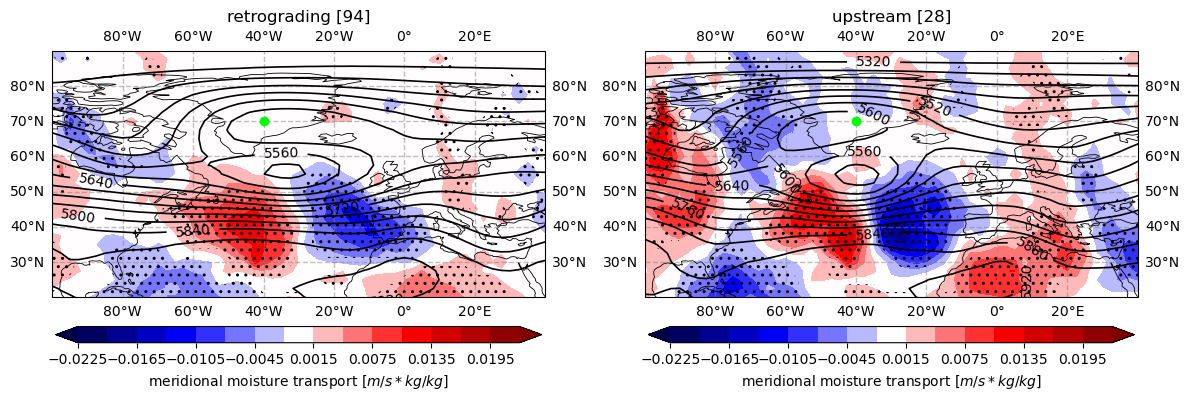

In [6]:
# Example data (you need to provide your own data for these variables)
# zg_comp, plon, plat, lon, lat, anom_comp should be defined in your script

fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(12, 4), subplot_kw={'projection': ccrs.PlateCarree()})

lon = ds['lon']
lon_comp = ds_comp['x']*2.5 - 180

titles = ['retrograding [' + str(counter_east) + ']','upstream [' + str(counter_west) + ']']
fields = [zg_comp_east,zg_comp_west]
anom_comp = [anom_comp_east,anom_comp_west]
t_st = [t_st_anom_east,t_st_anom_west]
extent = [-100, 40, 20, 90]  # Greenland
# extent =[-180,180,20,90] # Europe

for i,ax in enumerate(axarr):  # Loop over both axes
    ax.set_extent(extent, ccrs.PlateCarree())
    ax.coastlines(linewidth=0.6)
    
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                      linewidth=1, color='gray', alpha=0.5, linestyle='--')
    gl.xlabels_top = False
    gl.ylabels_left = False
    
    if False:
        lat_min, lat_max = 60, 80
        lon_min, lon_max = -70, -20
        # Plot the rectangle
        rect = plt.Rectangle((lon_min, lat_min), lon_max-lon_min, lat_max-lat_min,
                             edgecolor='red', facecolor='none', linewidth=2,
                             transform=ccrs.PlateCarree())
        ax.add_patch(rect)

    if True:
        ax.plot(plon,
               plat,
               marker='o',
               color='lime',
               transform=ccrs.PlateCarree())

    cont = ax.contour(lon, lat, fields[i],
                      colors='black',
                      alpha=1.,
                      linewidths=1.2,
                      levels=np.arange(4600, 7200, 40).astype(int))
    
    #c_range = np.array(np.arange(-np.amax(abs(anom_comp_west)), +np.amax(abs(anom_comp_west)), np.amax(abs(anom_comp_west))/8)) + np.array(np.amax(abs(anom_comp_west))/16)
    c_range = np.arange(-0.0225, 0.023, 0.003)
    #ticks = np.array(np.arange(-np.amax(abs(anom_comp_west)), +np.amax(abs(anom_comp_west)), np.amax(abs(anom_comp_west))/4)) + np.array(np.amax(abs(anom_comp_west))/8)
    ticks = np.arange(-0.0225, 0.023, 0.006)

    plt.clabel(cont, inline=True, fontsize=10)

    shadings = ax.contourf(lon_comp, lat, anom_comp[i],
                           cmap='seismic',
                           extend='both',
                           levels=c_range)
    density=2
    hatchings = ax.contourf(
    lon_comp, lat, t_st[i],
    transform=ccrs.PlateCarree(),
    colors='none',
    levels=[.5,1.5],
    hatches=[density*'.',density*'.'],
    )
    #ax.contourf(lon_comp,lat, t_st[i], colors='none',levels=[1],hatch = '//')
    
    fig.colorbar(shadings,label='meridional moisture transport [$m/s * kg/kg$]',orientation = "horizontal" ,ticks = ticks,fraction=0.05,pad = 0.09 ,aspect = 30,ax=ax)

for i,ax in enumerate(axarr):
    ax.set_title(titles[i])

plt.tight_layout()
#plt.savefig('/Users/michelefilippucci/PLOTS/greenland_article/summer_composite_greenland_IVT_west_multiplot.png', dpi=300)


/tmp/ipykernel_204696/1449633099.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels(['Retrograding', 'Upstream'])
/tmp/ipykernel_204696/1449633099.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels(['Retrograding', 'Upstream'])


{'whiskers': [<matplotlib.lines.Line2D at 0x7fe737e36d50>,
 'caps': [<matplotlib.lines.Line2D at 0x7fe737e36fd0>,
 'boxes': [<matplotlib.patches.PathPatch at 0x7fe737e36ad0>,
 'medians': [<matplotlib.lines.Line2D at 0x7fe737e37250>,
 'fliers': [<matplotlib.lines.Line2D at 0x7fe737e37390>,
 'means': []}

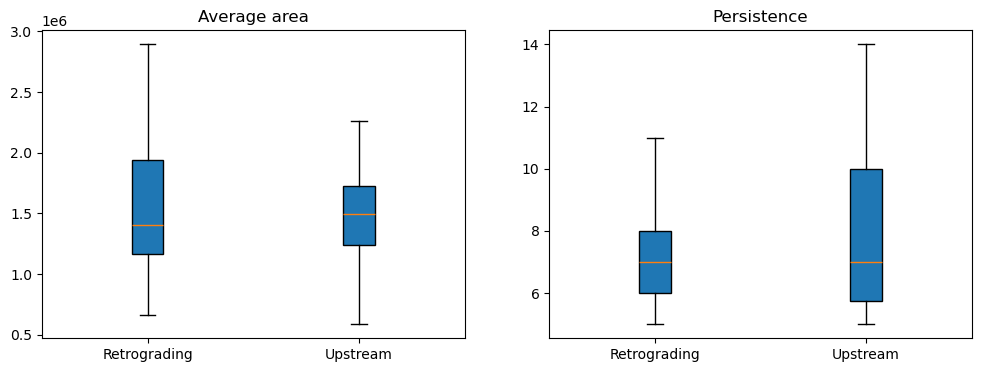

In [7]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
areas = [[],[]]
persistences = [[],[]]
for l in labels_east:
    areas[0].append(np.mean(dic[l]['area']))
    persistences[0].append(dic[l]['persistence'])
for l in labels_west:
    areas[1].append(np.mean(dic[l]['area']))
    persistences[1].append(dic[l]['persistence'])
axs[0].set_title('Average area')
axs[0].set_xticklabels(['Retrograding', 'Upstream'])
axs[0].boxplot(areas, vert=True, patch_artist=True)
axs[1].set_title('Persistence')
axs[1].set_xticklabels(['Retrograding', 'Upstream'])
axs[1].boxplot(persistences, vert=True, patch_artist=True)